In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline


In [2]:
data = load_breast_cancer()

X = pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y = pd.Series(
    (data.target==0).astype(int),
    name='malignant'
)

print(y.value_counts())
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("class names:",data.target_names)

malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix shape: (569, 30)
Target shape: (569,)
class names: ['malignant' 'benign']


In [3]:
class_counts = y.value_counts().sort_index()
class_distribution =pd.DataFrame({
    "Class": data.target_names,
    "Count": class_counts.values,
    "Probability": class_counts.values/len(y)
})
print(class_distribution)

       Class  Count  Probability
0  malignant    357     0.627417
1     benign    212     0.372583


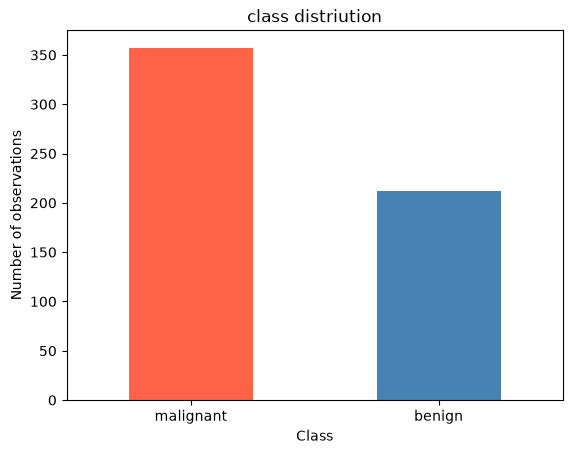

In [4]:
class_distribution.plot(
    x="Class",
    y="Count",
    kind="bar",
    legend=False,
    color=["tomato","steelblue"]
)

plt.ylabel("Number of observations")
plt.title("class distriution")
plt.xticks(rotation=0)
plt.show()

In [5]:
from sklearn.model_selection import train_test_split


In [6]:
X_train, X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("training size",len(y_train))
print("testing size",len(y_test))
print("Training propotions")
print(y_train.value_counts(normalize=True).sort_index())

training size 455
testing size 114
Training propotions
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64


In [7]:
model=make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [8]:
probabilites=model.predict_proba(X_test)
print(probabilites[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [9]:
print(probabilites[:5].sum(axis=1))

[1. 1. 1. 1. 1.]


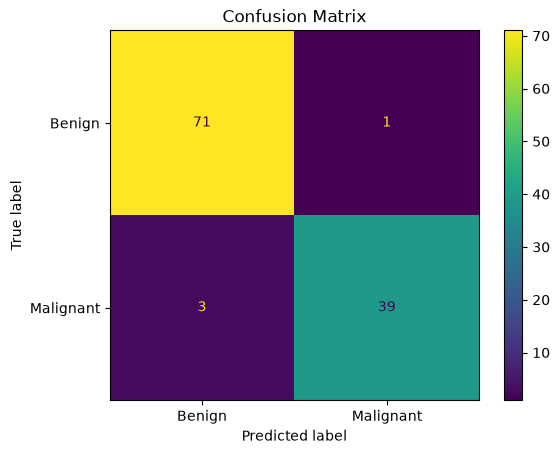

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
y_pred = model.predict(X_test)
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

In [ ]:
results=pd.DataFrame({
    "Actual class": y_test.values,
    "p_malignant": probabilites[:,0],
    "p_benign": probabilites[:,1]
})

print(results.head(10))

   Actual class   p_malignant  p_benign
0             0  9.996354e-01  0.000365
1             1  1.074660e-08  1.000000
2             0  9.574321e-01  0.042568
3             1  4.238127e-01  0.576187
4             0  4.908445e-01  0.509155
5             0  9.993840e-01  0.000616
6             1  2.384659e-01  0.761534
7             0  9.989878e-01  0.001012
8             0  9.994313e-01  0.000569
9             0  9.892324e-01  0.010768


In [12]:
results["Actual label"] = results["Actual class"].map({
    0: "Benign",
    1: "Malignant"
})

print(
    results[
        ["Actual label", "p_malignant", "p_benign"]
    ].head(10)
)

  Actual label   p_malignant  p_benign
0       Benign  9.996354e-01  0.000365
1    Malignant  1.074660e-08  1.000000
2       Benign  9.574321e-01  0.042568
3    Malignant  4.238127e-01  0.576187
4       Benign  4.908445e-01  0.509155
5       Benign  9.993840e-01  0.000616
6    Malignant  2.384659e-01  0.761534
7       Benign  9.989878e-01  0.001012
8       Benign  9.994313e-01  0.000569
9       Benign  9.892324e-01  0.010768


In [13]:
threshold = 0.50

results["Predicted_malignant"] = (
    results["p_malignant"] >= threshold
).astype(int)

results["Predicted_label"] = results[
    "Predicted_malignant"
].map({
    1: "Malignant",
    0: "Benign"
})

print(
    results[
        [
            "Actual label",
            "p_malignant",
            "Predicted_label"
        ]
    ].head(10)
)

  Actual label   p_malignant Predicted_label
0       Benign  9.996354e-01       Malignant
1    Malignant  1.074660e-08          Benign
2       Benign  9.574321e-01       Malignant
3    Malignant  4.238127e-01          Benign
4       Benign  4.908445e-01          Benign
5       Benign  9.993840e-01       Malignant
6    Malignant  2.384659e-01          Benign
7       Benign  9.989878e-01       Malignant
8       Benign  9.994313e-01       Malignant
9       Benign  9.892324e-01       Malignant


In [14]:
for threshold in [0.30, 0.50,0.70]:
    predictions=(
        results["p_malignant"] >=threshold
    ).astype(int)

    print(
        f"threshold ={threshold}:"
        f"Predicted malignnant cases = {predictions.sum()}"
    )

threshold =0.3:Predicted malignnant cases = 76
threshold =0.5:Predicted malignnant cases = 74
threshold =0.7:Predicted malignnant cases = 72


In [15]:
actual_malignant = (y_test.values == 0).astype(int)

for threshold in [0.30,0.50,0.70]:
    predicted_malignant = (
        probabilites[:,0]>= threshold
    ).astype(int)

    cm=confusion_matrix(
        actual_malignant,
        predicted_malignant
    )

    print(f"\nThreshold = {threshold}")
    print(cm)


Threshold = 0.3
[[38  4]
 [ 0 72]]

Threshold = 0.5
[[39  3]
 [ 1 71]]

Threshold = 0.7
[[41  1]
 [ 1 71]]


In [16]:
from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print(
    "Sklearn Accuracy",
    accuracy_score(y_test , y_pred)
)

print(
    "Sklearn precision",
    precision_score(y_test,y_pred)
)

print(
    "Sklearn recall",
    recall_score(y_test,y_pred)
)

print(
    "Sklearn f1_score",
    f1_score(y_test,y_pred)
)

Sklearn Accuracy 0.9649122807017544
Sklearn precision 0.975
Sklearn recall 0.9285714285714286
Sklearn f1_score 0.9512195121951219


In [17]:
thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

result_s = []

for i in thresholds:
    y_pred=(
        probabilites[:,1] >=i
        ).astype(int)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1score = f1_score(y_test, y_pred)

    result_s.append({
        "threshold": i,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1score": f1score
    })

result_s = pd.DataFrame(result_s)

print(result_s)

   threshold  accuracy  precision    recall   f1score
0        0.1  0.947368   0.891304  0.976190  0.931818
1        0.3  0.982456   0.976190  0.976190  0.976190
2        0.5  0.964912   0.975000  0.928571  0.951220
3        0.7  0.964912   1.000000  0.904762  0.950000
4        0.9  0.921053   1.000000  0.785714  0.880000
